# Semantic segmentation — quickstart

**Semantic segmentation** classifies every *pixel*: road, sky, tumour, defect, background. The output is an image the same size as the input, where each pixel holds a class id. It doesn't separate individual objects — two touching circles are one 'circle' region.

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 5 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/segmentation/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("segmentation", cfg)
print("task:", "segmentation", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: segmentation | data: data/demo/segmentation | outputs: outputs/segmentation_quick


## 1 · The data
A few examples, with their labels:

classes: {0: 'background', 1: 'circle', 2: 'square', 3: 'triangle'}


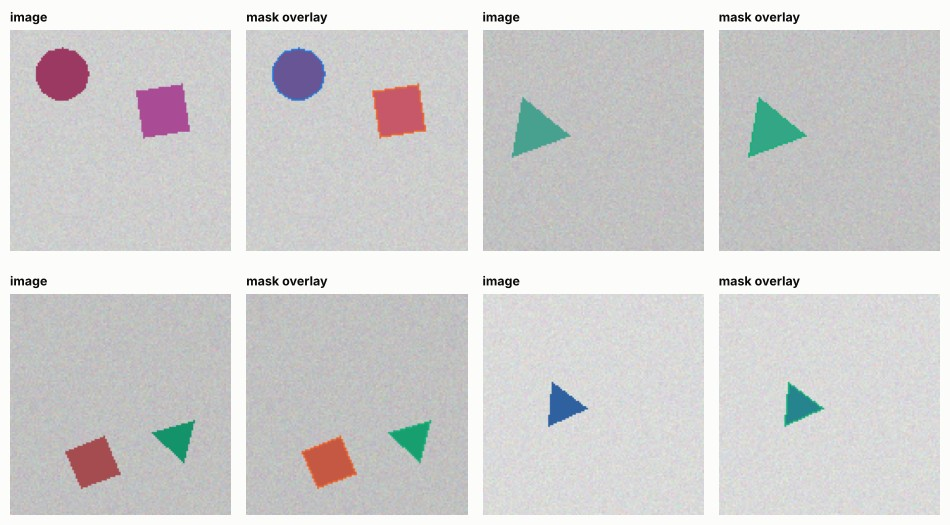

In [3]:
import numpy as np
from PIL import Image
from cvkit.viz import image_grid, overlay_label_map
from tasks.segmentation.data import build_datasets, read_mask

ds = build_datasets(cfg)
classes, pairs = ds["classes"], ds["pairs"]
print("classes:", dict(enumerate(classes)))
shown, titles = [], []
for img_path, mask_path in pairs[:4]:
    im = Image.open(img_path).convert("RGB")
    shown += [im, overlay_label_map(im, read_mask(mask_path).numpy())]
    titles += ["image", "mask overlay"]
_ = image_grid(shown, titles, cols=4, cell=2.4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit segmentation train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.segmentation.train import train

result = train(cfg)

arch: unet_resnet18 | classes (4): ['background', 'circle', 'square', 'triangle']
device: cpu | parameters: 14,321,220 total, 14,321,220 trainable (100.0%)


epoch   1/40 | train_loss 1.2295 | val miou=0.223 mdice=0.236 pixel_acc=0.894 | 6.9s  <- best


epoch   2/40 | train_loss 0.8138 | val miou=0.352 mdice=0.396 pixel_acc=0.935 | 6.6s  <- best


epoch   3/40 | train_loss 0.6185 | val miou=0.352 mdice=0.398 pixel_acc=0.935 | 6.4s  <- best


epoch   4/40 | train_loss 0.5045 | val miou=0.382 mdice=0.447 pixel_acc=0.937 | 6.4s  <- best


...

epoch  36/40 | train_loss 0.0610 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.5s  <- best


epoch  37/40 | train_loss 0.0604 | val miou=0.910 mdice=0.952 pixel_acc=0.993 | 6.7s


epoch  38/40 | train_loss 0.0641 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.5s


epoch  39/40 | train_loss 0.0580 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.4s


epoch  40/40 | train_loss 0.0622 | val miou=0.912 mdice=0.953 pixel_acc=0.993 | 6.5s
best val miou = 0.9119 (epoch 36) -> outputs/segmentation_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.segmentation.evaluate import evaluate

metrics = evaluate(cfg)

mean IoU 0.945 | mean Dice 0.972 | pixel accuracy 0.995 (45 test images)
background           IoU 0.998   Dice 0.999
circle               IoU 0.953   Dice 0.976
square               IoU 0.917   Dice 0.957
triangle             IoU 0.914   Dice 0.955
reports -> outputs/segmentation_quick/reports


per_class_iou.png


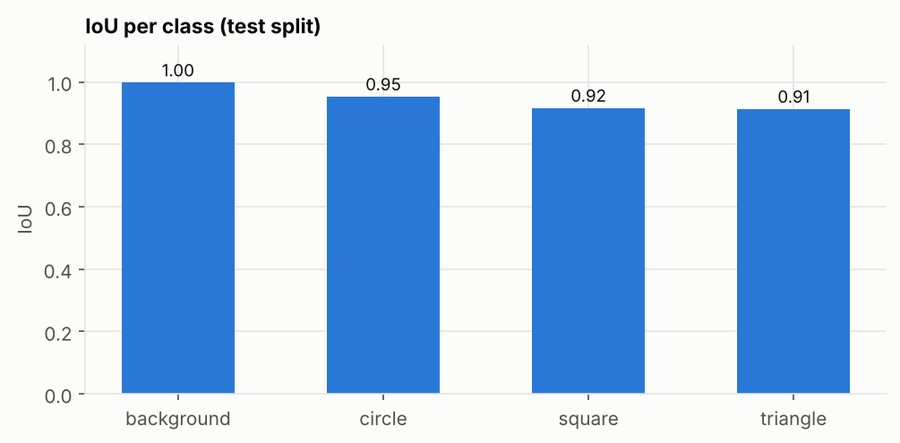

confusion_matrix.png


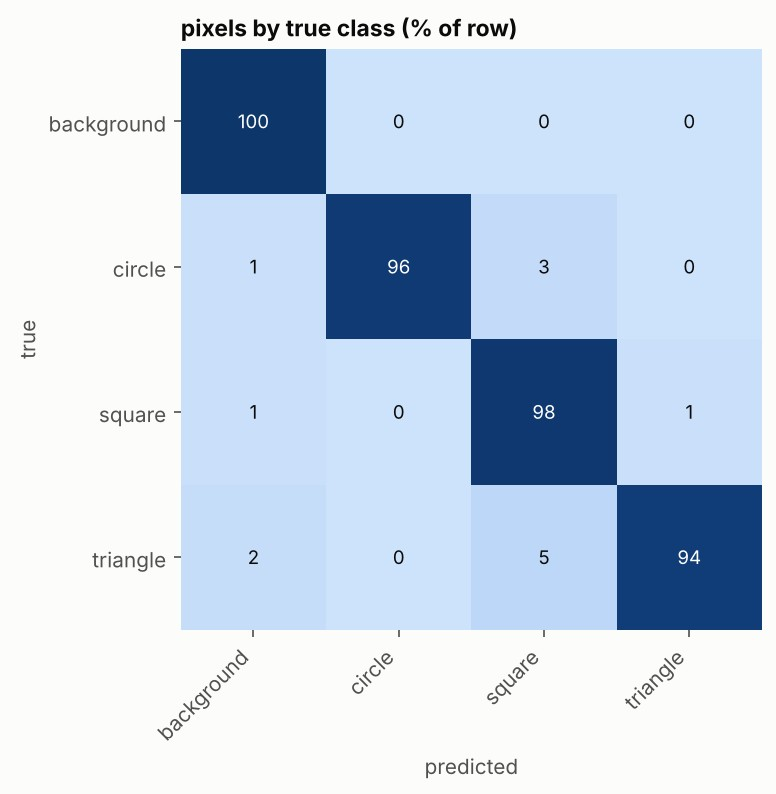

predictions.png


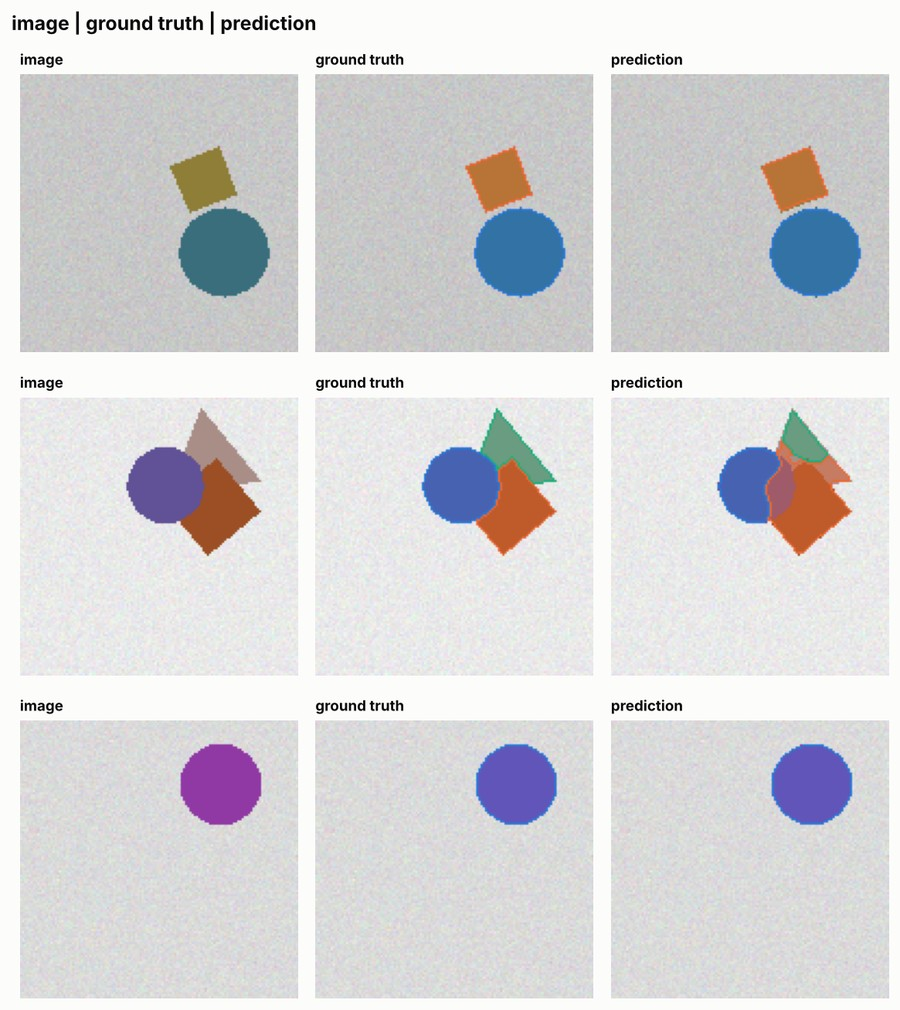

worst_images.png


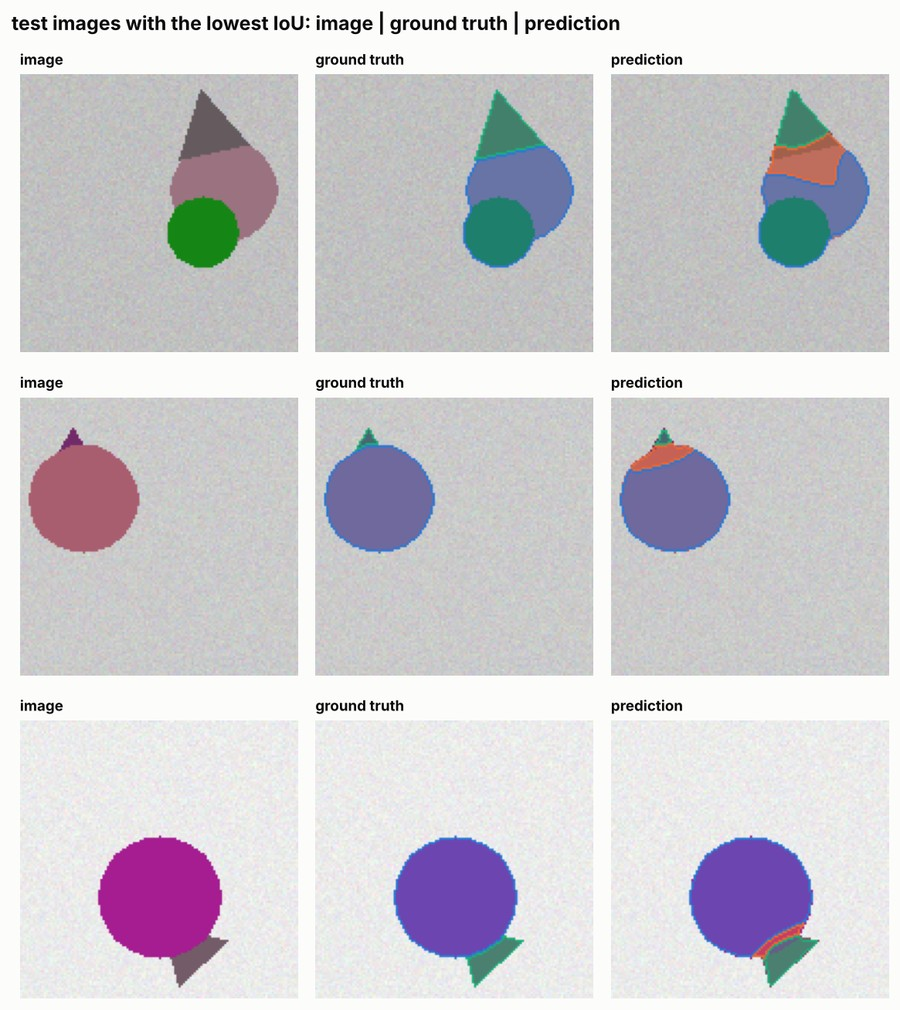

In [6]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['per_class_iou.png', 'confusion_matrix.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

**Reading it:** `predictions.png` shows image | ground truth | prediction. **IoU per class** is the headline: shared pixels ÷ pixels either mask covers. Pixel accuracy alone can look great when the background is most of the image.

## 4 · Predict
`Predictor.predict` returns a `(H, W)` array of class ids at the image's own size:

mask: (128, 128) uint8 | class ids present: [0, 1, 2]


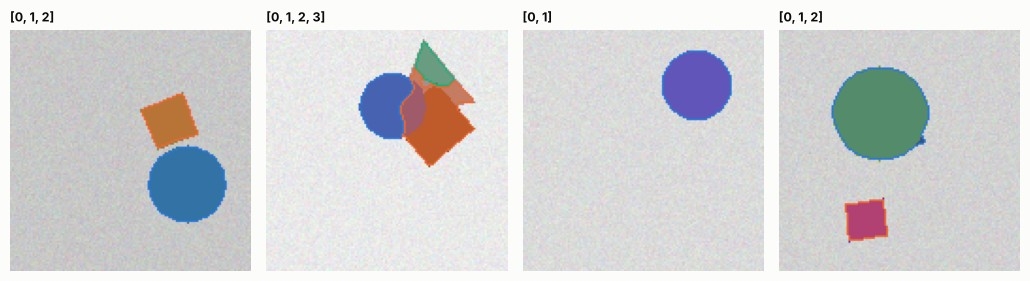

In [7]:
from cvkit.viz import image_grid
from tasks.segmentation.predict import Predictor
from tasks.segmentation.data import test_image_paths

predictor = Predictor.from_config(cfg)
paths = test_image_paths(cfg, 4)
masks = [predictor.predict(p) for p in paths]
print("mask:", masks[0].shape, masks[0].dtype, "| class ids present:", sorted(set(masks[0].ravel().tolist())))
_ = image_grid([predictor.visualize(p, m) for p, m in zip(paths, masks)], [str(sorted(set(m.ravel().tolist()))) for m in masks], cols=4, cell=2.6)

## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)